# 01 · Frame the Problem & Explore the Data
**Project:** Predicting hotel booking cancellations — a Proof of Value for revenue management

This notebook covers the first two sections of the ML Project Checklist (Géron, Appendix B):
1. **Frame the problem and look at the big picture**
2. **Explore the data** — profile every attribute, visualise, study correlations, spot leakage,
   list promising transformations and extra data, and summarise what we learned.

Modelling is in `02_prepare_and_shortlist.ipynb`; tuning and the final test in `03_finetune_and_evaluate.ipynb`.

## 1. Frame the problem

| Question | Answer |
|---|---|
| **Objective** | Reduce revenue lost to cancellations. 37% of bookings in this data are cancelled; every cancellation that is not re-sold is an empty room. |
| **Who uses it, and how** | The **revenue-management team** of each hotel. Each booking is scored **once, when it is created** (new bookings are scored in a nightly batch; open bookings are re-scored only when the model is retrained monthly), using only information known at booking time — most cancellations happen weeks before arrival (median ≈ 7 weeks, §6), so a late warning would be useless. The team uses the scores to (a) decide **how many rooms to overbook** per night, and (b) send **targeted actions** to high-risk bookings (reminder e-mail, a "confirm your stay" offer, or a deposit request). |
| **Current solution / workaround** | Rules of thumb: a flat overbooking rate per season, or the historical cancellation rate of the booking's market segment and deposit type. We implement the second as our **business baseline**. |
| **ML framing** | **Supervised, binary classification** (`is_canceled`), on tabular data. **Offline / batch** learning: retrain monthly, score new bookings in a nightly batch; no need for online learning because booking behaviour changes over weeks, not minutes. |
| **Performance measure** | **ROC-AUC** (main, ranking quality — the team works down a list sorted by risk) and **PR-AUC / average precision** (focuses on the cancelled class). For the deployed decision we choose a **probability threshold** that minimises a **business cost** (missed cancellation = 1 empty room, false alarm = c; base case c = 0.5, sensitivity c = 0.25–4) on validation predictions, and report precision/recall at that threshold. |
| **Is the metric aligned with the objective?** | Mostly. Accuracy would be misleading (63% by predicting "no cancellation"). AUC rewards correct *ordering*, which is what an action list needs; precision at the threshold controls the cost of bothering guests who will actually show up. The true objective is monetary, so in notebook 03 we also translate the confusion matrix into rooms and euros. |
| **Evaluation protocol** | **Out-of-time test set**: train on arrivals Jul-2015 → Apr-2017, test on arrivals May → Aug-2017. This mimics deployment (learn from the past, predict the future) and is stricter than a random split. Tuning and model selection use **forward-in-time validation** inside the training period (notebook 03); the test set is used once, with bootstrap confidence intervals. |

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # make `src` importable when run from notebooks/

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.features import (FIG_DIR, LEAKY_COLUMNS, POST_BOOKING_COLUMNS, TARGET, basic_clean, load_raw,
                          temporal_split)

FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
PALETTE = {0: "#4C72B0", 1: "#DD8452"}


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 2. Get the data
Source: *Hotel booking demand* (Kaggle, jessemostipak), originally published by Antonio, Almeida & Nunes (2019),
*Data in Brief* 22. Two hotels in Portugal (a **City Hotel** in Lisbon and a **Resort Hotel** in the Algarve),
arrivals between **1 Jul 2015 and 31 Aug 2017**. Each row is one booking.

In [2]:
raw = load_raw()
print(raw.shape)
raw.head()

(119390, 33)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,arrival_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02,2015-07-01
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02,2015-07-01
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03,2015-07-01


### Set the test set aside *before* exploring
To avoid data-snooping bias we split first and explore **only the training set**. The split is temporal
(arrivals from 1 May 2017 onwards go to test).

In [3]:
train_raw, test_raw = temporal_split(raw)
print(f"train: {len(train_raw):,} rows  ({train_raw.arrival_date.min():%Y-%m-%d} → {train_raw.arrival_date.max():%Y-%m-%d})")
print(f"test : {len(test_raw):,} rows  ({test_raw.arrival_date.min():%Y-%m-%d} → {test_raw.arrival_date.max():%Y-%m-%d})")
print(f"test share: {len(test_raw)/len(raw):.1%}")
print(f"cancellation rate  train={train_raw[TARGET].mean():.3f}  test={test_raw[TARGET].mean():.3f}")
df = train_raw.copy()   # exploration copy

train: 97,192 rows  (2015-07-01 → 2017-04-30)
test : 22,198 rows  (2017-05-01 → 2017-08-31)
test share: 18.6%
cancellation rate  train=0.362  test=0.405


## 3. Study each attribute
The table below profiles all 32 original attributes: type, % missing, number of distinct values,
an example, the cancellation-rate spread across its values, and our verdict on usefulness and noise.

In [4]:
def profile(frame: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for c in frame.columns:
        s = frame[c]
        kind = ("datetime" if pd.api.types.is_datetime64_any_dtype(s) else
                "numeric" if pd.api.types.is_numeric_dtype(s) else "categorical")
        rows.append({
            "attribute": c,
            "dtype": str(s.dtype),
            "kind": kind,
            "% missing": round(100 * s.isna().mean(), 2),
            "n_unique": s.nunique(),
            "example": s.dropna().iloc[0],
            "min": s.min() if kind == "numeric" else None,
            "max": s.max() if kind == "numeric" else None,
            "skew": round(s.skew(), 2) if kind == "numeric" else None,
        })
    return pd.DataFrame(rows).set_index("attribute")


prof = profile(df.drop(columns=["arrival_date"]))
prof

,dtype,kind,% missing,n_unique,example,min,max,skew
attribute,,,,,,,,
hotel,str,categorical,0.00,2,Resort Hotel,NaN,NaN,NaN
is_canceled,int64,numeric,0.00,2,0,0.00,1.0,0.57
lead_time,int64,numeric,0.00,453,342,0.00,737.0,1.48
arrival_date_year,int64,numeric,0.00,3,2015,2015.00,2017.0,0.03
arrival_date_month,str,categorical,0.00,12,July,NaN,NaN,NaN
arrival_date_week_number,int64,numeric,0.00,53,27,1.00,53.0,-0.06
arrival_date_day_of_month,int64,numeric,0.00,31,1,1.00,31.0,-0.01
stays_in_weekend_nights,int64,numeric,0.00,17,0,0.00,19.0,1.54
stays_in_week_nights,int64,numeric,0.00,35,0,0.00,50.0,3.19


**Attribute-by-attribute notes** (type · distribution · noise · usefulness)

| Attribute | Type | Distribution / noise | Usefulness |
|---|---|---|---|
| `is_canceled` | binary **target** | 36% positive in train → mildly imbalanced | target |
| `hotel` | categorical (2) | City 2/3, Resort 1/3 | high – City cancels much more |
| `lead_time` | int, unbounded ≥0 | strongly right-skewed (log-normal-like), max > 700 days | **very high** |
| `arrival_date_year/month/week/day` | int / categorical | roughly uniform within year, seasonal peaks in summer | medium – decompose into month & weekday; *year* will not generalise |
| `stays_in_weekend/week_nights` | int, bounded | skewed, a few stays of 30+ nights (real long stays, kept) | medium |
| `adults`, `children`, `babies` | int | mostly 2 adults; a few rows with 0 guests (errors), a couple with 10 babies (noise) | low-medium |
| `meal` | categorical (5) | `Undefined` and `SC` both mean "no meal" | low |
| `country` | categorical (~170) | 0.4% missing; PRT dominates; **suspected partial leakage** (see §5, §7) | high but risky |
| `market_segment`, `distribution_channel` | categorical | `Undefined` codes (7 rows) = missing | high – Groups / Online TA cancel more |
| `is_repeated_guest`, `previous_cancellations`, `previous_bookings_not_canceled` | int | very sparse (>95% zero) | medium – previous cancellations is strong when present |
| `reserved_room_type` | categorical (10) | letters, anonymised | low-medium |
| `assigned_room_type` | categorical | **set at check-in → leakage** | dropped |
| `booking_changes` | int | 85% zero | **excluded** — accumulates after the booking is made (§6) |
| `deposit_type` | categorical (3) | `Non Refund` = 12% of rows | **very high** (counter-intuitive, see §5) |
| `agent` | ID as float (~330) | 14% missing = booked without agent | high – some agents are cancellation hot-spots |
| `company` | ID as float | **94% missing** | only usable as a "has company" flag |
| `days_in_waiting_list` | int | 97% zero, long tail | low |
| `customer_type` | categorical (4) | Transient dominates | medium |
| `adr` | float (EUR) | right-skewed, 1 negative value and 1 outlier at 5,400 (errors) | medium – price sensitivity |
| `required_car_parking_spaces` | int | 94% zero | looks very high (*nobody* who asked for parking cancelled) but **excluded** — likely confirmed after booking (§6) |
| `total_of_special_requests` | int 0-5 | skewed | looks high but **excluded** — requests are added after booking (§6) |
| `reservation_status`, `reservation_status_date` | categorical / date | **is the outcome** | dropped (target leakage) |

### Missing values

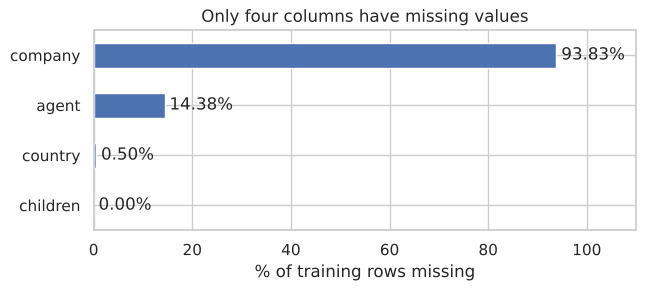

In [5]:
miss = (df.isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]
fig, ax = plt.subplots(figsize=(7, 2.6))
miss.plot.barh(ax=ax, color="#4C72B0")
for i, v in enumerate(miss):
    ax.text(v + 1, i, f"{v:.2f}%", va="center")
ax.set_xlabel("% of training rows missing"); ax.set_xlim(0, 110)
ax.set_title("Only four columns have missing values")
ax.invert_yaxis(); save(fig, "eda_missing"); plt.show()

**Takeaway:** missingness is concentrated and *meaningful*. `company` (94%) and `agent` (14%) are missing
because no company/agent was involved — we encode them as "has_company" / "agent = 0" rather than imputing.
`country` (0.4%) and `children` (4 rows) are imputed with a constant / 0.

### Data-quality issues (noise)

In [6]:
guests = df.adults + df.children.fillna(0) + df.babies
checks = {
    "bookings with 0 guests": (guests == 0).sum(),
    "negative adr": (df.adr < 0).sum(),
    "adr > 1000 EUR": (df.adr > 1000).sum(),
    "0-night stays": ((df.stays_in_weekend_nights + df.stays_in_week_nights) == 0).sum(),
    "'Undefined' codes (meal/segment/channel)": ((df.meal == "Undefined") | (df.market_segment == "Undefined") | (df.distribution_channel == "Undefined")).sum(),
    "exact duplicate rows": df.drop(columns="arrival_date").duplicated().sum(),
}
pd.Series(checks, name="rows").to_frame()

,rows
bookings with 0 guests,159
negative adr,1
adr > 1000 EUR,1
0-night stays,666
'Undefined' codes (meal/segment/channel),1115
exact duplicate rows,27532


**Takeaway:**
* 0-guest bookings, negative and extreme `adr` are entry errors → removed (≈ 0.2% of rows).
* 0-night stays are kept (day-use rooms exist) and handled by the engineered `total_nights` feature.
* **~28% of rows are exact duplicates.** There is no booking ID, so these are most likely
  multi-room *group* bookings entered as one row per room (58% of duplicated rows are cancellations,
  vs 36% overall). They are real bookings, so we **keep** them — but in cross-validation we put identical
  rows in the same fold (`StratifiedGroupKFold`), otherwise the model would be tested on rows it memorised.

## 4. Target and key relationships

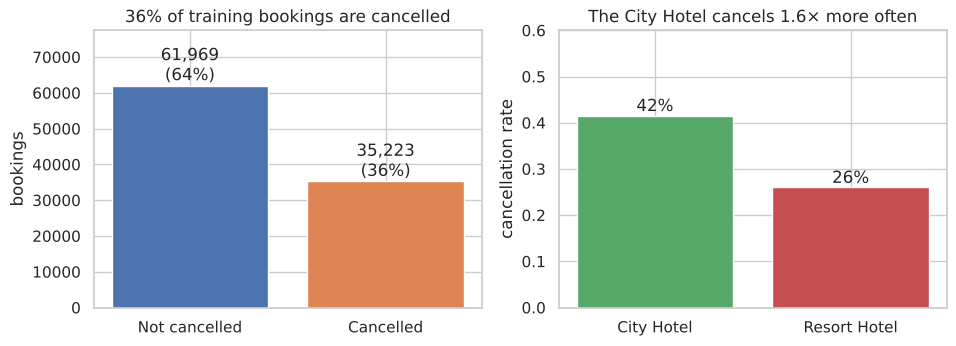

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
counts = df[TARGET].value_counts().sort_index()
axes[0].bar(["Not cancelled", "Cancelled"], counts.values, color=[PALETTE[0], PALETTE[1]])
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}\n({v/len(df):.0%})", ha="center", va="bottom")
axes[0].set_ylim(0, counts.max() * 1.25); axes[0].set_ylabel("bookings")
axes[0].set_title("36% of training bookings are cancelled")
rate = df.groupby("hotel")[TARGET].mean()
axes[1].bar(rate.index, rate.values, color=["#55A868", "#C44E52"])
for i, v in enumerate(rate.values):
    axes[1].text(i, v + 0.01, f"{v:.0%}", ha="center")
axes[1].set_ylim(0, 0.6); axes[1].set_ylabel("cancellation rate")
axes[1].set_title("The City Hotel cancels 1.6× more often")
save(fig, "eda_target"); plt.show()

**Takeaway:** the classes are imbalanced but not extremely (36/64) — no resampling needed, but accuracy
is a poor metric (64% for a model that always says "will show up"). The two hotels behave differently,
so `hotel` must be a feature (or we could train one model per hotel).

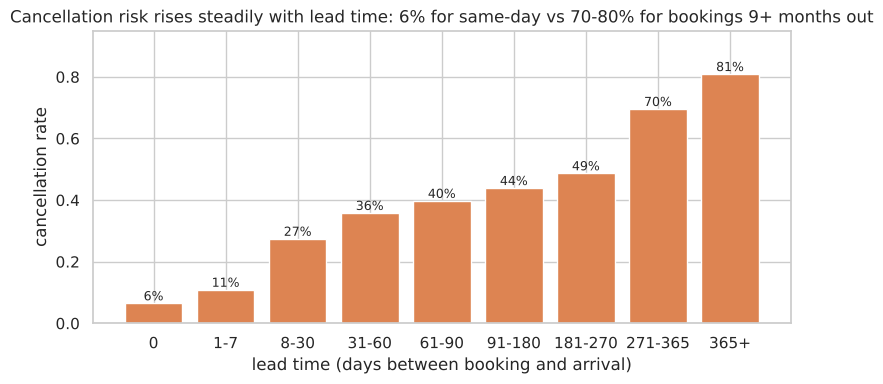

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.8))
bins = [-1, 0, 7, 30, 60, 90, 180, 270, 365, 800]
labels = ["0", "1-7", "8-30", "31-60", "61-90", "91-180", "181-270", "271-365", "365+"]
lt = pd.cut(df.lead_time, bins=bins, labels=labels)
g = df.groupby(lt, observed=True)[TARGET].agg(["mean", "size"])
ax.bar(g.index.astype(str), g["mean"], color="#DD8452")
for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
    ax.text(i, m + 0.01, f"{m:.0%}", ha="center", fontsize=9)
ax.set_xlabel("lead time (days between booking and arrival)"); ax.set_ylabel("cancellation rate")
ax.set_ylim(0, 0.95)
ax.set_title("Cancellation risk rises steadily with lead time: 6% for same-day vs 70-80% for bookings 9+ months out")
save(fig, "eda_lead_time"); plt.show()

**Takeaway:** `lead_time` is the single strongest numeric signal and the relationship is monotonic but
non-linear (fast rise in the first month, a plateau between 1 and 9 months, then another jump) → a
`log1p(lead_time)` transform should help linear models,
while trees will capture it directly. Its distribution is heavily right-skewed:

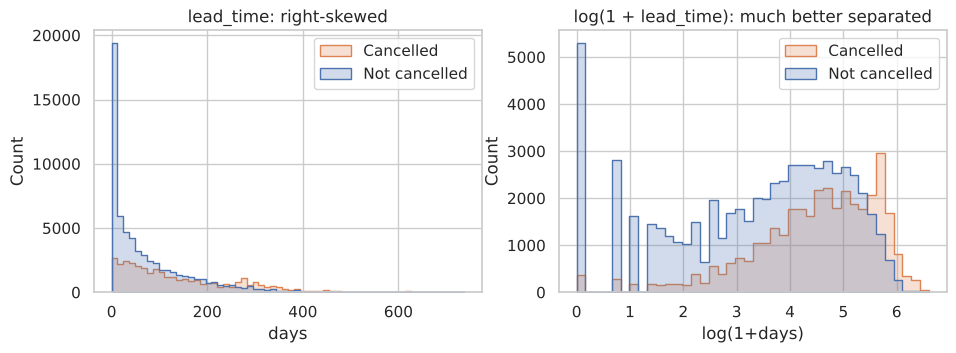

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
sns.histplot(data=df, x="lead_time", hue=TARGET, bins=60, palette=PALETTE, ax=axes[0], element="step")
axes[0].set_title("lead_time: right-skewed"); axes[0].set_xlabel("days")
sns.histplot(data=df.assign(log_lead=np.log1p(df.lead_time)), x="log_lead", hue=TARGET, bins=40,
             palette=PALETTE, ax=axes[1], element="step")
axes[1].set_title("log(1 + lead_time): much better separated"); axes[1].set_xlabel("log(1+days)")
for a in axes: a.legend(title="", labels=["Cancelled", "Not cancelled"])
save(fig, "eda_lead_time_dist"); plt.show()

## 5. Categorical drivers

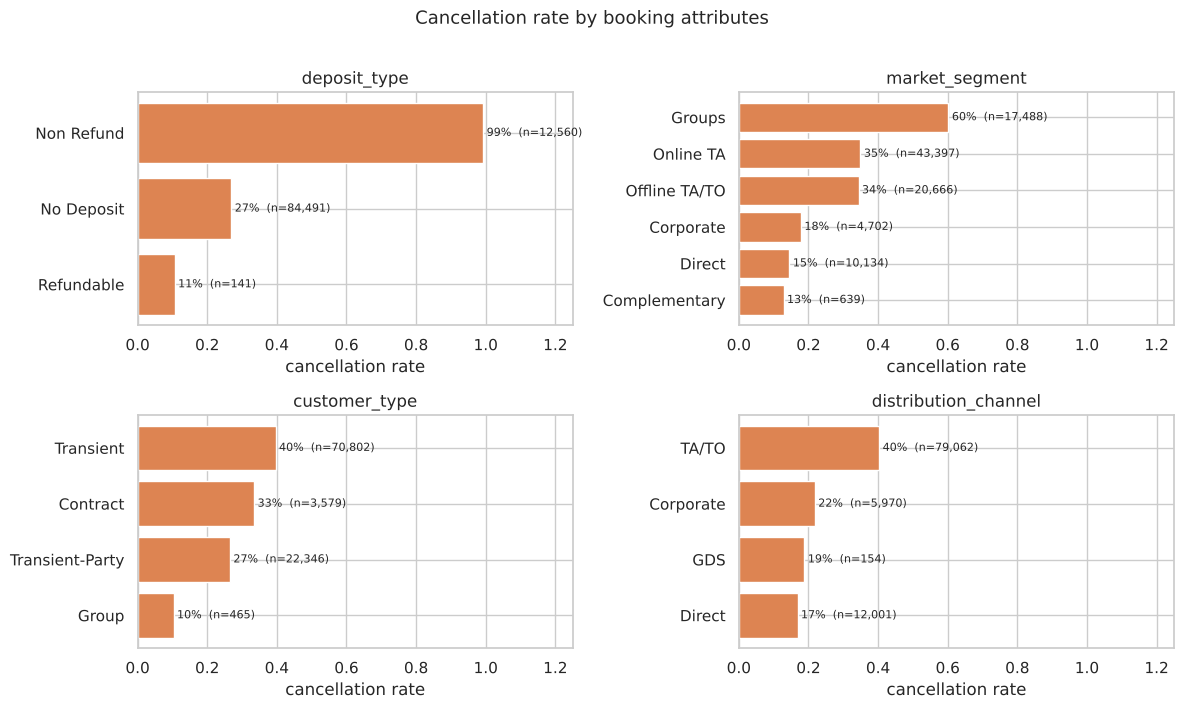

In [10]:
def rate_plot(col, ax, top=None, min_n=200):
    g = df.groupby(col)[TARGET].agg(["mean", "size"])
    g = g[g["size"] >= min_n].sort_values("mean")
    if top: g = g.tail(top)
    ax.barh(g.index.astype(str), g["mean"], color="#DD8452")
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(m + 0.01, i, f"{m:.0%}  (n={n:,})", va="center", fontsize=8)
    ax.set_xlim(0, 1.25); ax.set_xlabel("cancellation rate"); ax.set_title(col)


fig, axes = plt.subplots(2, 2, figsize=(12, 7))
rate_plot("deposit_type", axes[0, 0], min_n=50)
rate_plot("market_segment", axes[0, 1])
rate_plot("customer_type", axes[1, 0])
rate_plot("distribution_channel", axes[1, 1], min_n=150)
fig.suptitle("Cancellation rate by booking attributes", y=1.01, fontsize=13)
fig.tight_layout(); save(fig, "eda_categoricals"); plt.show()

In [11]:
# Who makes the non-refundable bookings?
nr = df[df.deposit_type == "Non Refund"]
print("market segment:", nr.market_segment.value_counts(normalize=True).round(3).head(3).to_dict())
print("country       :", nr.country.value_counts(normalize=True).round(3).head(3).to_dict())
print(f"median lead time: {nr.lead_time.median():.0f} days (all bookings: {df.lead_time.median():.0f})")
print(f"share that are exact duplicate rows: {nr.drop(columns='arrival_date').duplicated(keep=False).mean():.1%}")

market segment: {'Groups': 0.623, 'Offline TA/TO': 0.348, 'Corporate': 0.024}
country       : {'PRT': 0.969, 'GBR': 0.011, 'ESP': 0.01}
median lead time: 197 days (all bookings: 60)
share that are exact duplicate rows: 98.4%


**Takeaways:**
* **`Non Refund` deposits cancel 99% of the time** — the opposite of intuition. The data hints at why
  (see the cell below): 97% of non-refundable bookings come from **Groups or Offline tour operators**, 97% are
  recorded as **Portugal**, their median lead time is **197 days** (vs 60 overall) and 98% are **duplicate rows**.
  They look like *room blocks* that operators reserve far in advance and release later, not individual guests
  who forfeited money. For the business this is a key insight: **deposit type alone flags 1 in 3
  cancellations with almost no false alarms** — and the team should audit how these blocks are recorded.
* **Groups** (60%) and **Online travel agents** (35%) cancel most; Direct and Corporate bookings are reliable.
* Booking **channel** and **segment** carry overlapping information (TA/TO ≈ Online + Offline TA).

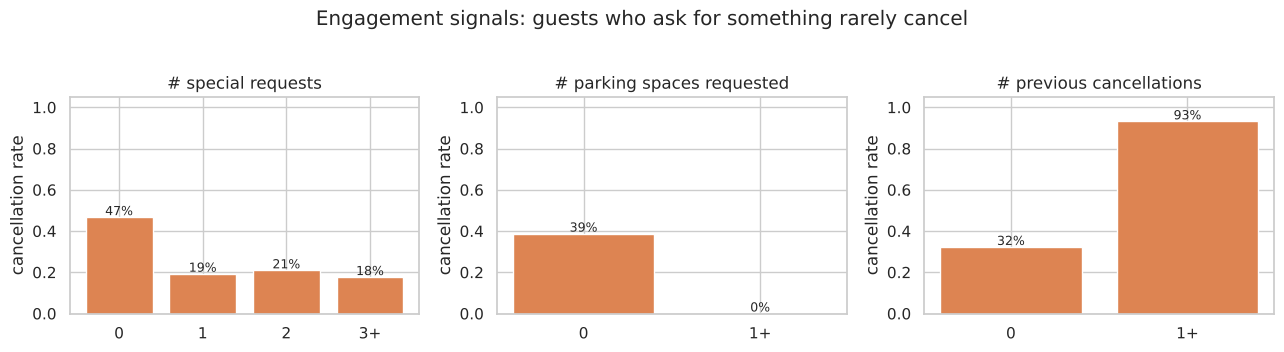

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, col, title in zip(axes,
                          ["total_of_special_requests", "required_car_parking_spaces", "previous_cancellations"],
                          ["# special requests", "# parking spaces requested", "# previous cancellations"]):
    cap = 1 if col != "total_of_special_requests" else 3
    s = df[col].clip(upper=cap)
    g = df.groupby(s)[TARGET].mean()
    ax.bar([str(i) if i < cap else f"{cap}+" for i in g.index], g.values, color="#DD8452")
    for i, v in enumerate(g.values):
        ax.text(i, v + 0.01, f"{v:.0%}", ha="center", fontsize=9)
    ax.set_ylim(0, 1.05); ax.set_title(title); ax.set_ylabel("cancellation rate")
fig.suptitle("Engagement signals: guests who ask for something rarely cancel", y=1.03)
fig.tight_layout(); save(fig, "eda_engagement"); plt.show()

**Takeaway:** "engagement" variables are powerful. **No guest who requested a parking space cancelled.**
One special request cuts the risk from 47% to 19%. Conversely, 93% of guests with at least one previous
cancellation cancel again. This suggests a `prev_cancel_ratio` feature.

⚠️ But *when* are parking and special requests recorded? A 0% cancellation rate among 7,000+ parking requests is
"too perfect", and guests often add requests (or confirm parking) after booking or at arrival. We return to this
in §6 — these columns turn out to be unsafe for a model used at booking time.

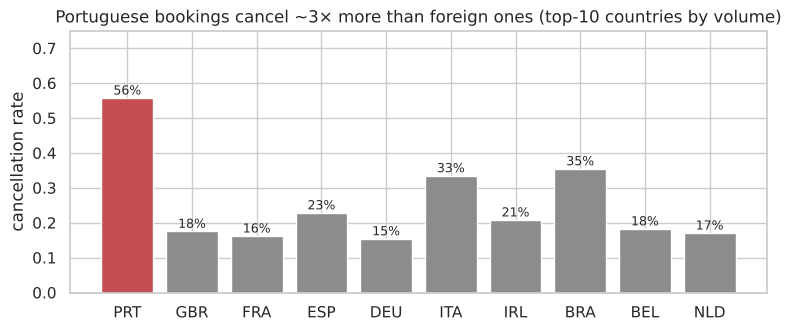

In [13]:
top_c = df.country.value_counts().head(10).index
g = df[df.country.isin(top_c)].groupby("country")[TARGET].agg(["mean", "size"]).sort_values("size", ascending=False)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(g.index, g["mean"], color=["#C44E52" if c == "PRT" else "#8C8C8C" for c in g.index])
for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
    ax.text(i, m + 0.01, f"{m:.0%}", ha="center", fontsize=9)
ax.set_ylabel("cancellation rate"); ax.set_ylim(0, 0.75)
ax.set_title("Portuguese bookings cancel ~3× more than foreign ones (top-10 countries by volume)")
save(fig, "eda_country"); plt.show()

**Takeaway & warning:** PRT bookings cancel far more (≈ 56%) than any other top-10 country (15–35%).
Part of this is real (domestic guests book speculatively, and most non-refundable group blocks are coded PRT),
**but** the dataset paper (Antonio, Almeida & Nunes, 2019) warns that *"it is also common for hotels not to
know the correct nationality of the customer until the moment of check-in."* If nationality is corrected
only for guests who arrive, a *cancelled* booking keeps its initial (often domestic) value — so `country` may be
**partially leaky**. We cannot verify this from the data, so we treat it as an
experiment in notebook 02 (model with vs. without `country`) instead of trusting it blindly.

## 6. When do cancellations happen? → when must the model predict?
`reservation_status_date` is the date the booking was cancelled. It can never be a feature, but it tells us how
far ahead of arrival cancellations occur — which decides **when** the model must produce its prediction.

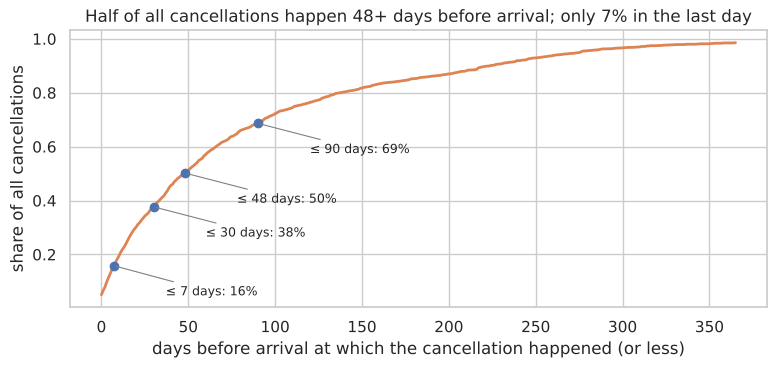

median: 48 days before arrival; 84% of cancellations happen more than a week ahead


In [14]:
canc = df[df[TARGET] == 1]
days_before = (canc.arrival_date - pd.to_datetime(canc.reservation_status_date)).dt.days
fig, ax = plt.subplots(figsize=(9, 3.6))
xs = np.arange(0, 366)
ax.plot(xs, [(days_before <= x).mean() for x in xs], color="#DD8452", lw=2)
for x in [7, 30, int(days_before.median()), 90]:
    yv = (days_before <= x).mean()
    ax.plot([x], [yv], "o", color="#4C72B0")
    ax.annotate(f"≤ {x} days: {yv:.0%}", (x, yv), xytext=(x + 30, yv - 0.11), fontsize=9,
                arrowprops=dict(arrowstyle="-", color="grey", lw=0.8))
ax.set_xlabel("days before arrival at which the cancellation happened (or less)")
ax.set_ylabel("share of all cancellations")
ax.set_title(f"Half of all cancellations happen {days_before.median():.0f}+ days before arrival; only "
             f"{(days_before <= 1).mean():.0%} in the last day")
save(fig, "eda_cancellation_timing"); plt.show()
print(f"median: {days_before.median():.0f} days before arrival; "
      f"{(days_before > 7).mean():.0%} of cancellations happen more than a week ahead")

**Takeaway — this sets the prediction time.** 84% of cancellations happen more than a week before arrival
(median ≈ 7 weeks). A model that only works close to arrival would warn the hotel *after* most cancellations had
already happened. **The model must predict at booking time**, so it may only use information that exists when the
booking is created. Columns that are filled in or updated later — `total_of_special_requests`,
`required_car_parking_spaces`, `booking_changes` — are excluded from the main model (they are tested only as an
"upper bound" in notebook 03).

## 7. Leakage audit
Features must be available **at booking time**. We checked every column:

In [15]:
pd.crosstab(df.reservation_status, df[TARGET], margins=True)

is_canceled,0,1,All
reservation_status,,,
Canceled,0,34181,34181
Check-Out,61969,0,61969
No-Show,0,1042,1042
All,61969,35223,97192


In [16]:
changed = (df.reserved_room_type != df.assigned_room_type)
print("Share of bookings whose room was changed (assigned ≠ reserved):")
print(changed.groupby(df[TARGET]).mean().rename({0: "not cancelled", 1: "cancelled"}).round(3))

Share of bookings whose room was changed (assigned ≠ reserved):
is_canceled
not cancelled    0.209
cancelled        0.020
dtype: float64


| Column | Verdict | Why |
|---|---|---|
| `reservation_status` | **drop** | `Canceled`/`No-Show` ⇔ `is_canceled = 1`. It *is* the target. |
| `reservation_status_date` | **drop** | Date of the final outcome — only known afterwards. |
| `assigned_room_type` | **drop** | Assigned at check-in; 21% of stays get a different room vs 2% of cancellations → would leak "the guest arrived". |
| `country` | **ablation** | Nationality may only be corrected at check-in (dataset paper, see §5). Tested with/without. |
| `total_of_special_requests`, `required_car_parking_spaces`, `booking_changes` | **drop (main model)** | Filled in or updated *after* the booking is created (the dataset paper extracted values as of the day before arrival). Not available when the prediction is needed (§6). Kept only for an upper-bound check. |
| `deposit_type`, `days_in_waiting_list` | keep | Set when the booking is confirmed (deposit policy, time on the waiting list before confirmation). Listed as an assumption. |

Including the first three columns gives a near-perfect model that would be useless in production — a
classic Proof-of-Value trap we want to show we avoided. The second group is subtler: they are not the outcome,
but using them would make the model look better than it can be at the moment it is needed.

## 8. Correlations

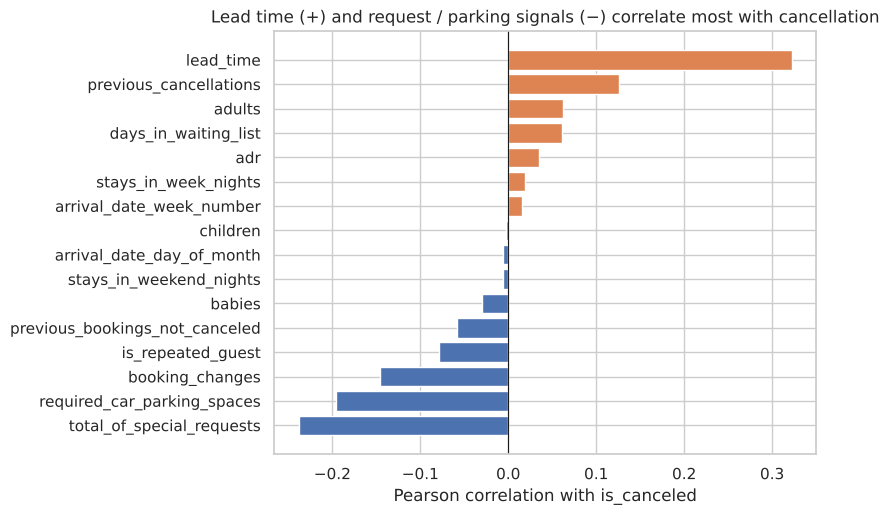

In [17]:
num = df.select_dtypes("number").drop(columns=["arrival_date_year", "agent", "company"])  # IDs are not quantities
corr_t = num.corr(numeric_only=True)[TARGET].drop(TARGET).sort_values()
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(corr_t.index, corr_t.values, color=["#4C72B0" if v < 0 else "#DD8452" for v in corr_t.values])
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Pearson correlation with is_canceled")
ax.set_title("Lead time (+) and request / parking signals (−) correlate most with cancellation")
save(fig, "eda_corr_target"); plt.show()

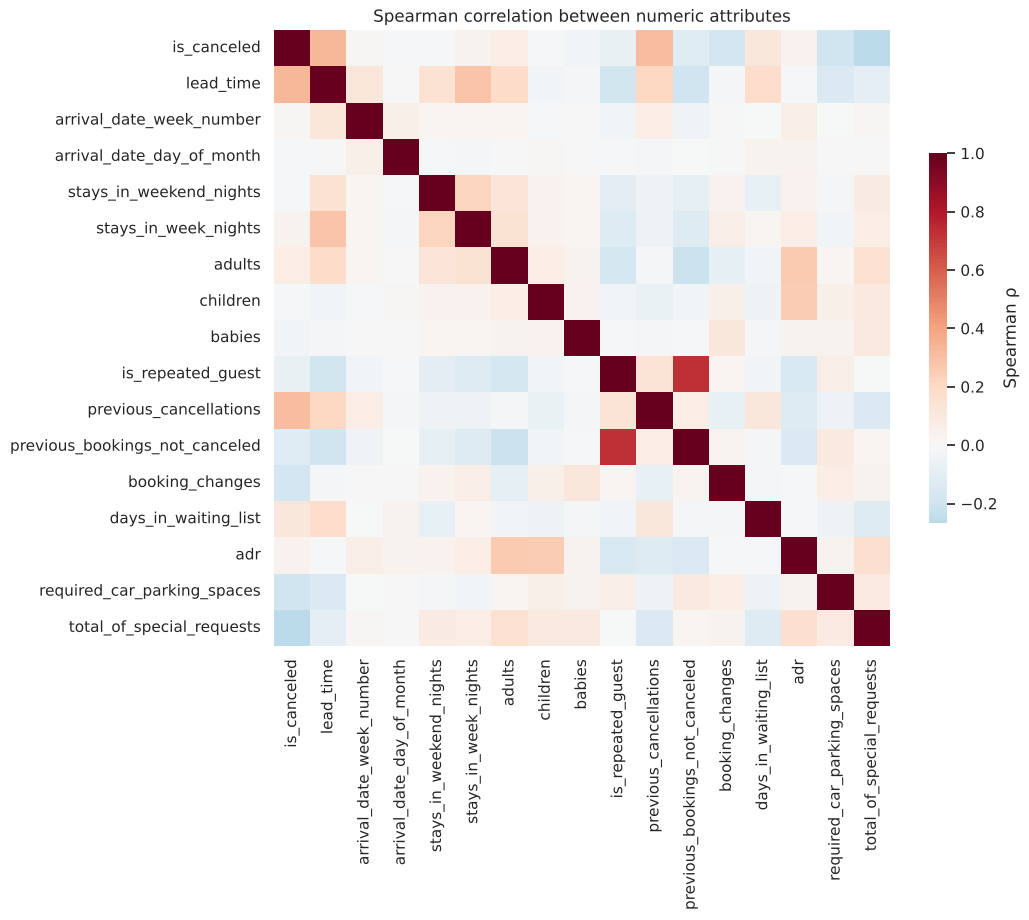

In [18]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(num.corr(method="spearman"), cmap="RdBu_r", center=0, ax=ax, square=True,
            cbar_kws={"shrink": .6, "label": "Spearman ρ"}, xticklabels=True, yticklabels=True)
ax.set_title("Spearman correlation between numeric attributes")
save(fig, "eda_corr_heatmap"); plt.show()

**Takeaways:**
* No single numeric feature is strongly linearly correlated with the target (|r| ≤ 0.32, lead time) → the signal is
  spread out and partly non-linear / interaction-based, which favours tree ensembles.
* Strong correlations *between* inputs: week-nights ↔ weekend-nights, `is_repeated_guest` ↔
  `previous_bookings_not_canceled`, `arrival_date_week_number` ↔ month. Not a problem for trees; for linear
  models we rely on regularisation.
* Categorical variables (deposit type, segment, country) are stronger than any numeric one — Pearson
  correlation alone would under-rate them.

## 9. Seasonality and drift

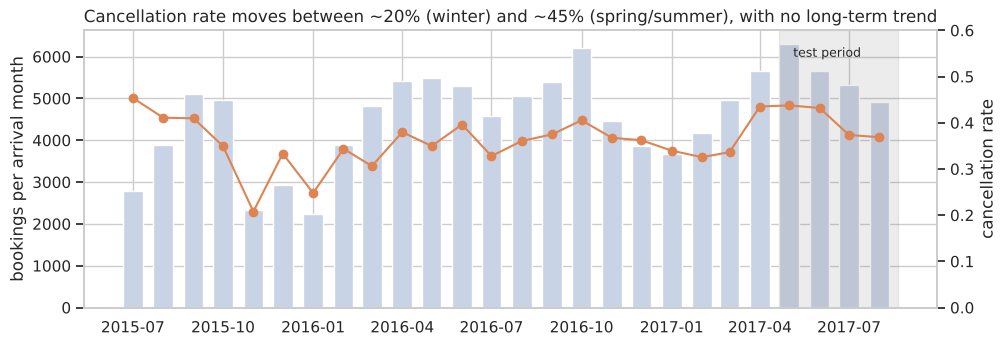

In [19]:
m = raw.set_index("arrival_date").resample("MS")[TARGET].agg(["mean", "size"])
fig, ax1 = plt.subplots(figsize=(11, 3.6))
ax1.bar(m.index, m["size"], width=20, color="#C9D3E6", label="bookings")
ax1.set_ylabel("bookings per arrival month")
ax2 = ax1.twinx()
ax2.plot(m.index, m["mean"], color="#DD8452", marker="o", label="cancellation rate")
ax2.set_ylabel("cancellation rate"); ax2.set_ylim(0, 0.6); ax2.grid(False)
ax1.axvspan(pd.Timestamp("2017-04-20"), pd.Timestamp("2017-08-20"), color="grey", alpha=0.15)
ax1.text(pd.Timestamp("2017-05-05"), m["size"].max() * 0.95, "test period", fontsize=9)
ax1.set_title("Cancellation rate moves between ~20% (winter) and ~45% (spring/summer), with no long-term trend")
save(fig, "eda_time"); plt.show()

**Takeaway:** the cancellation rate varies with season but has no strong trend, so a model trained on
2015-2017Q1 should transfer to summer 2017. 2015 only starts in July — so `arrival_date_year` would just
learn "which partial year", and we drop it. Month and day-of-week (of arrival *and* of booking) are kept.

## 10. Promising transformations & extra data

**Transformations to try (implemented in `src/features.py`):**
* `log1p(lead_time)` – fixes skew, captures the saturating effect.
* `total_nights`, `total_guests`, `has_kids`, `weekend_share` – aggregate the stay description.
* `adr_per_guest`, `total_revenue` – price relative to party size; value at stake.
* Decompose dates: arrival month & weekday, **booking** month & weekday (arrival − lead time).
* `prev_cancel_ratio`, `has_history` – customer track record.
* Flags: `has_agent`, `has_company`.
* High-cardinality IDs (`agent`, `country`): group rare levels (< 50 bookings) into "infrequent".

**Extra data that would help:** a booking ID and booking timestamp (to dedupe group bookings and score at a
precise moment), **time-stamped change logs** (to know when requests / parking / changes were added, so they
could be used safely), the **price paid vs. the current public price** (guests cancel to rebook cheaper),
competitor prices, the cancellation-policy deadline, local events/holidays, weather, and customer
loyalty/CRM data.

## 11. Summary of what we learned
1. **36% of training bookings cancel**; City Hotel 42% vs Resort 26%.
2. **Lead time is the #1 numeric driver** — risk grows from 6% (same-day) to 70-80% (9+ months ahead).
3. **Non-refundable deposits cancel 99% of the time** — counter-intuitive but explainable (group/TO blocks).
4. **Past cancellers repeat** (93%). Special and parking requests look very protective, but are recorded after booking.
5. **Cancellations happen early** (median ≈ 7 weeks before arrival) → the model must predict **at booking time**.
6. **Three columns leak the target** (`reservation_status`, its date, `assigned_room_type`) and three more are
   only known after booking (special requests, parking, booking changes) → all dropped from the main model;
   `country` is suspicious and will be tested.
7. **28% duplicate rows** (likely group bookings) → kept, but grouped in CV.
8. Signal is spread over many weakly-correlated features and interactions → expect **tree ensembles** to win.
9. Data errors are rare (≈ 0.2% of rows) and removed in `basic_clean()`.

In [20]:
clean = basic_clean(raw)
print(f"rows removed by basic_clean: {len(raw) - len(clean)} ({(len(raw) - len(clean))/len(raw):.2%})")
print("leaky columns dropped later:", LEAKY_COLUMNS)
print("post-booking columns dropped from the main model:", POST_BOOKING_COLUMNS)

rows removed by basic_clean: 182 (0.15%)
leaky columns dropped later: ['reservation_status', 'reservation_status_date', 'assigned_room_type']
post-booking columns dropped from the main model: ['required_car_parking_spaces', 'total_of_special_requests', 'booking_changes']
